
Training with learning rate = 0.03
Epoch 001/500 | Train Loss: 1.609438 | Val Loss: 1.565831 | Train Acc: 0.2003 | Val Acc: 0.6821
Epoch 002/500 | Train Loss: 1.566430 | Val Loss: 1.525534 | Train Acc: 0.6832 | Val Acc: 0.6848
Epoch 003/500 | Train Loss: 1.526682 | Val Loss: 1.488443 | Train Acc: 0.6868 | Val Acc: 0.6874
Epoch 004/500 | Train Loss: 1.490091 | Val Loss: 1.454409 | Train Acc: 0.6895 | Val Acc: 0.6898
Epoch 005/500 | Train Loss: 1.456510 | Val Loss: 1.423247 | Train Acc: 0.6918 | Val Acc: 0.6914
Epoch 006/500 | Train Loss: 1.425756 | Val Loss: 1.394744 | Train Acc: 0.6940 | Val Acc: 0.6931
Epoch 007/500 | Train Loss: 1.397619 | Val Loss: 1.368671 | Train Acc: 0.6963 | Val Acc: 0.6949
Epoch 008/500 | Train Loss: 1.371877 | Val Loss: 1.344800 | Train Acc: 0.6985 | Val Acc: 0.6969
Epoch 009/500 | Train Loss: 1.348300 | Val Loss: 1.322903 | Train Acc: 0.7005 | Val Acc: 0.6989
Epoch 010/500 | Train Loss: 1.326669 | Val Loss: 1.302770 | Train Acc: 0.7024 | Val Acc: 0.7001
Epoc

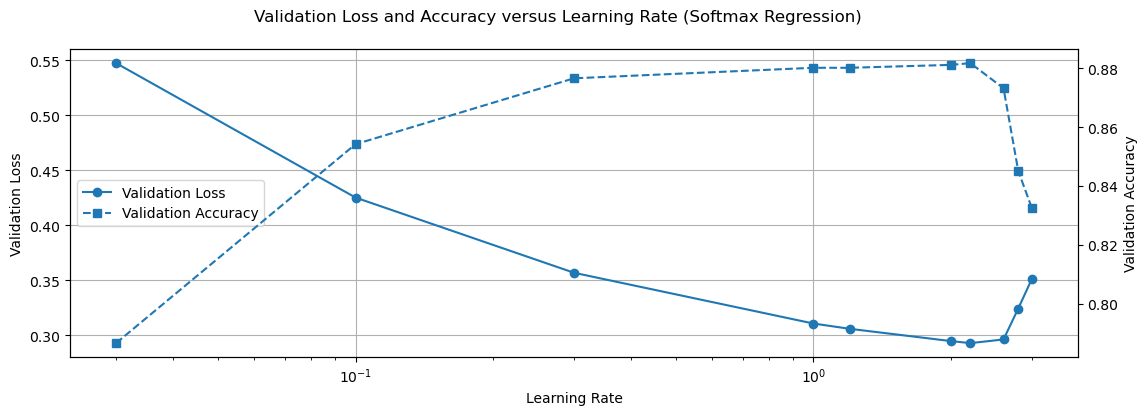

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from Model import SoftmaxLogisticTrainer
from prepare_data import X_train, y_train, X_val, y_val

# ===== learning rate sweep =====
lr_list = [ 3e-2, 1e-1, 3e-1, 1.0, 1.2,2.0,2.2, 2.6, 2.8, 3.0] 
val_losses_lr = []
val_accs_lr = []

for lr in lr_list:
    print(f"\nTraining with learning rate = {lr}")

    trainer = SoftmaxLogisticTrainer(
        lr=lr,
        l2=1e-4,      # cố định L2
        epochs=500
    )

    trainer.fit(
        X_train, y_train,
        X_val, y_val,
        patience=20
    )

    val_losses_lr.append(min(trainer.val_losses))
    val_accs_lr.append(max(trainer.val_accs))

# ===== plot =====
fig, ax1 = plt.subplots(figsize=(13,4))

ax1.set_xscale('log')
ax1.plot(lr_list, val_losses_lr, 'o-', label='Validation Loss')
ax1.set_xlabel('Learning Rate')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(lr_list, val_accs_lr, 's--', label='Validation Accuracy')
ax2.set_ylabel('Validation Accuracy')

fig.suptitle('Validation Loss and Accuracy versus Learning Rate (Softmax Regression)')

ax1.grid(True)

# legend chung
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center left')

plt.show()




Training with L2 = 0
Epoch 001/500 | Train Loss: 1.609438 | Val Loss: 0.767400 | Train Acc: 0.2003 | Val Acc: 0.6821
Epoch 002/500 | Train Loss: 0.773235 | Val Loss: 0.671518 | Train Acc: 0.6832 | Val Acc: 0.7989
Epoch 003/500 | Train Loss: 0.677030 | Val Loss: 0.616373 | Train Acc: 0.7961 | Val Acc: 0.7530
Epoch 004/500 | Train Loss: 0.620979 | Val Loss: 0.579518 | Train Acc: 0.7545 | Val Acc: 0.8037
Epoch 005/500 | Train Loss: 0.584081 | Val Loss: 0.553441 | Train Acc: 0.8003 | Val Acc: 0.7674
Epoch 006/500 | Train Loss: 0.557399 | Val Loss: 0.533112 | Train Acc: 0.7683 | Val Acc: 0.8063
Epoch 007/500 | Train Loss: 0.537043 | Val Loss: 0.517313 | Train Acc: 0.8016 | Val Acc: 0.7744
Epoch 008/500 | Train Loss: 0.520810 | Val Loss: 0.503943 | Train Acc: 0.7750 | Val Acc: 0.8100
Epoch 009/500 | Train Loss: 0.507471 | Val Loss: 0.493041 | Train Acc: 0.8041 | Val Acc: 0.7771
Epoch 010/500 | Train Loss: 0.496232 | Val Loss: 0.483306 | Train Acc: 0.7793 | Val Acc: 0.8144
Epoch 011/500 | Tr

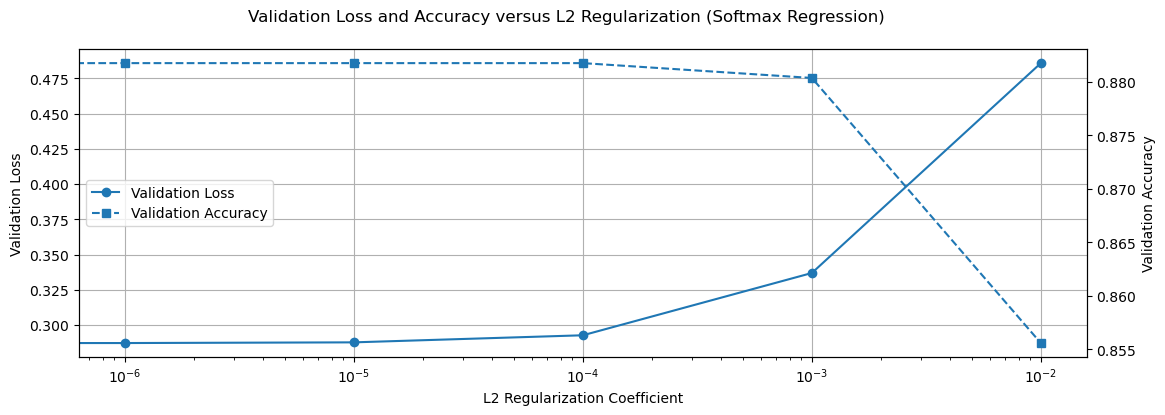

In [3]:
l2_list = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
val_losses_l2 = []
val_accs_l2 = []

for l2 in l2_list:
    print(f"\nTraining with L2 = {l2}")

    trainer = SoftmaxLogisticTrainer(
        lr=2.2,     # lr đã chọn
        l2=l2,
        epochs=500
    )

    trainer.fit(
        X_train, y_train,
        X_val, y_val,
        patience=20
    )

    val_losses_l2.append(min(trainer.val_losses))
    val_accs_l2.append(max(trainer.val_accs))

# ===== plot =====
fig, ax1 = plt.subplots(figsize=(13,4))

ax1.set_xscale('log')
ax1.plot(l2_list, val_losses_l2, 'o-', label='Validation Loss')
ax1.set_xlabel('L2 Regularization Coefficient')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(l2_list, val_accs_l2, 's--', label='Validation Accuracy')
ax2.set_ylabel('Validation Accuracy')

fig.suptitle('Validation Loss and Accuracy versus L2 Regularization (Softmax Regression)')

ax1.grid(True)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center left')

plt.show()


Epoch 001/500 | Train Loss: 1.609438 | Val Loss: 0.767400 | Train Acc: 0.2003 | Val Acc: 0.6821
Epoch 002/500 | Train Loss: 0.773235 | Val Loss: 0.671593 | Train Acc: 0.6832 | Val Acc: 0.7989
Epoch 003/500 | Train Loss: 0.677106 | Val Loss: 0.616510 | Train Acc: 0.7961 | Val Acc: 0.7530
Epoch 004/500 | Train Loss: 0.621118 | Val Loss: 0.579711 | Train Acc: 0.7545 | Val Acc: 0.8039
Epoch 005/500 | Train Loss: 0.584278 | Val Loss: 0.553683 | Train Acc: 0.8003 | Val Acc: 0.7674
Epoch 006/500 | Train Loss: 0.557645 | Val Loss: 0.533400 | Train Acc: 0.7683 | Val Acc: 0.8063
Epoch 007/500 | Train Loss: 0.537337 | Val Loss: 0.517642 | Train Acc: 0.8016 | Val Acc: 0.7742
Epoch 008/500 | Train Loss: 0.521146 | Val Loss: 0.504311 | Train Acc: 0.7750 | Val Acc: 0.8102
Epoch 009/500 | Train Loss: 0.507846 | Val Loss: 0.493445 | Train Acc: 0.8041 | Val Acc: 0.7769
Epoch 010/500 | Train Loss: 0.496644 | Val Loss: 0.483744 | Train Acc: 0.7792 | Val Acc: 0.8144
Epoch 011/500 | Train Loss: 0.487023 | V

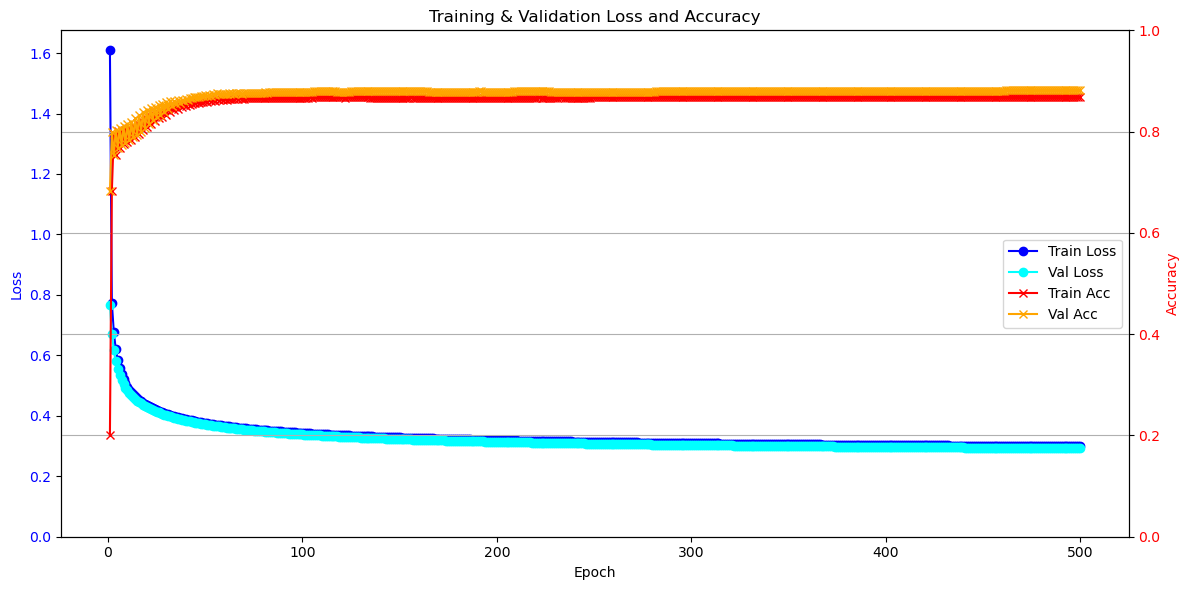

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from training_loop import trainer
from prepare_data import X_train, X_test,y_train,y_test

epochs = np.arange(1, len(trainer.train_losses) + 1)

fig, ax1 = plt.subplots(figsize=(12, 6))

# ===== LOSS (LEFT Y-AXIS) =====
ax1.plot(epochs, trainer.train_losses, 'o-', color='blue', label='Train Loss')
ax1.plot(epochs, trainer.val_losses, 'o-', color='cyan', label='Val Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(bottom=0)

# ===== ACCURACY (RIGHT Y-AXIS) =====
ax2 = ax1.twinx()
ax2.plot(epochs, trainer.train_accs, 'x-', color='red', label='Train Acc')
ax2.plot(epochs, trainer.val_accs, 'x-', color='orange', label='Val Acc')
ax2.set_ylabel('Accuracy', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0, 1.0)

# ===== TITLE =====
plt.title('Training & Validation Loss and Accuracy')

# ===== LEGEND (COMBINE BOTH AXES) =====
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.grid(True)
plt.tight_layout()
plt.show()


In [5]:
X_train.shape

(23555, 16)

In [6]:
import pickle
with open("softmax_logistic_model.pkl", "rb") as f:
    model = pickle.load(f)
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

In [7]:
Fault_types = [ 'BPFI',
                'BPFO',  
                'Misalign',
                'Normal',
                'Unbalance'
                ]

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score


def plot_multiclass_roc(model, X_test, y_test, Fault_types=None):
    """
    Plot ROC curves for multi-class classification using One-vs-Rest strategy

    Parameters
    ----------
    model : trained model
        Must implement predict_proba(X)
    X_test : array-like, shape (N, D)
        Test features
    y_test : array-like, shape (N,)
        True labels
    Fault_types : list of str, optional
        Names of classes (for legend)
    """

    # ===== Predict probabilities =====
    y_score = model.predict_proba(X_test)  # (N, C)
    n_classes = y_score.shape[1]

    # ===== Binarize labels =====
    y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

    # ===== Storage =====
    fpr = {}
    tpr = {}
    roc_auc = {}

    # ===== ROC per class =====
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # ===== Macro-average ROC =====
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))

    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

    mean_tpr /= n_classes

    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # ===== Plot =====
    plt.figure(figsize=(10, 6))

    plt.plot(
        fpr["macro"],
        tpr["macro"],
        linestyle="--",
        linewidth=3,
        label=f"Macro-average ROC (AUC = {roc_auc['macro']:.4f})"
    )

    for i in range(n_classes):
        label_name = f"Class {i}"
        if Fault_types is not None:
            label_name = Fault_types[i]

        plt.plot(
            fpr[i],
            tpr[i],
            linewidth=1.5,
            label=f"{label_name} (AUC = {roc_auc[i]:.4f})"
        )

    plt.plot([0, 1], [0, 1], "k--", linewidth=1)

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)

    plt.show()

    return roc_auc


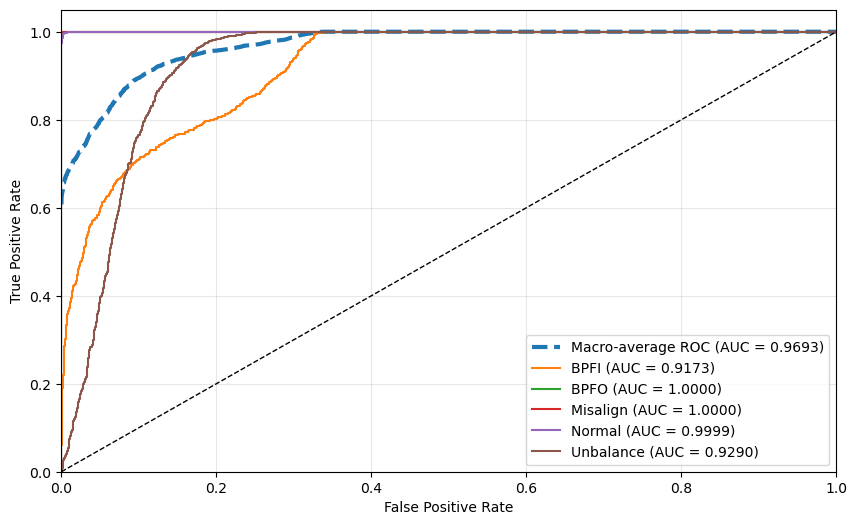

In [9]:
roc_auc = plot_multiclass_roc(
    model,
    X_test,
    y_test,
    Fault_types=Fault_types 
)


In [10]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score, precision_score
train_accuracy = accuracy_score(y_train, train_predict)
test_accuracy = accuracy_score(y_test, test_predict)

# --- Per-class metrics ---
# Recall per class
perclass_recall = recall_score(y_test, test_predict, average=None)
perclass_recall = [round(r, 4) for r in perclass_recall]

# Precision per class
perclass_precision = precision_score(y_test, test_predict, average=None, zero_division=0)
perclass_precision = [round(p, 4) for p in perclass_precision]

# F1 Score per class
perclass_f1 = f1_score(y_test, test_predict, average=None, zero_division=0)
perclass_f1 = [round(f, 4) for f in perclass_f1]

# Confusion Matrix
train_cm = confusion_matrix(y_train, train_predict)
test_cm = confusion_matrix(y_test, test_predict)

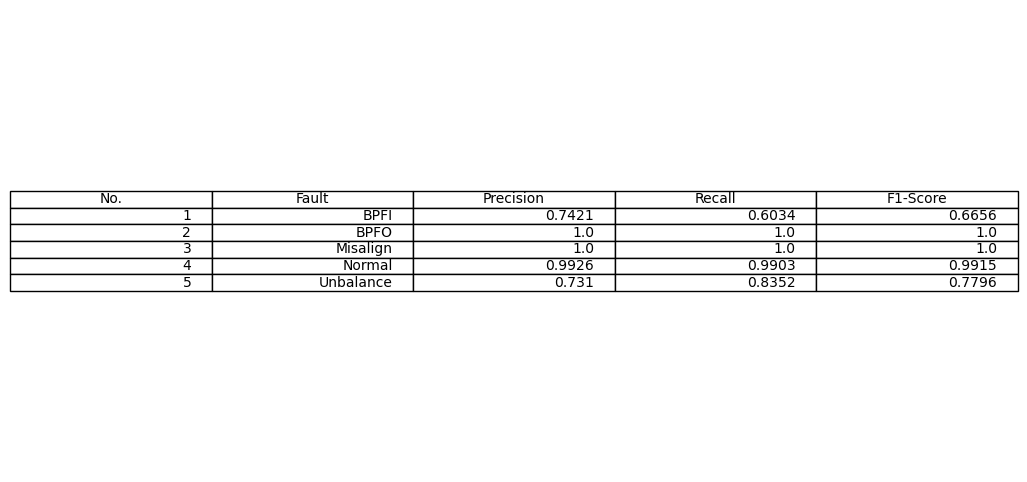

In [11]:
import pandas as pd
df_metrics = pd.DataFrame({
    "No.": range(1, len(Fault_types) + 1),
    "Fault": Fault_types,
    "Precision": perclass_precision,
    "Recall": perclass_recall,
    "F1-Score": perclass_f1,
})

# --- Plot table ---
fig, ax = plt.subplots(figsize=(13, 6))
ax.axis('tight')
ax.axis('off')
table = ax.table(cellText=df_metrics.values,
                 colLabels=df_metrics.columns,
                 loc='center')

plt.show()


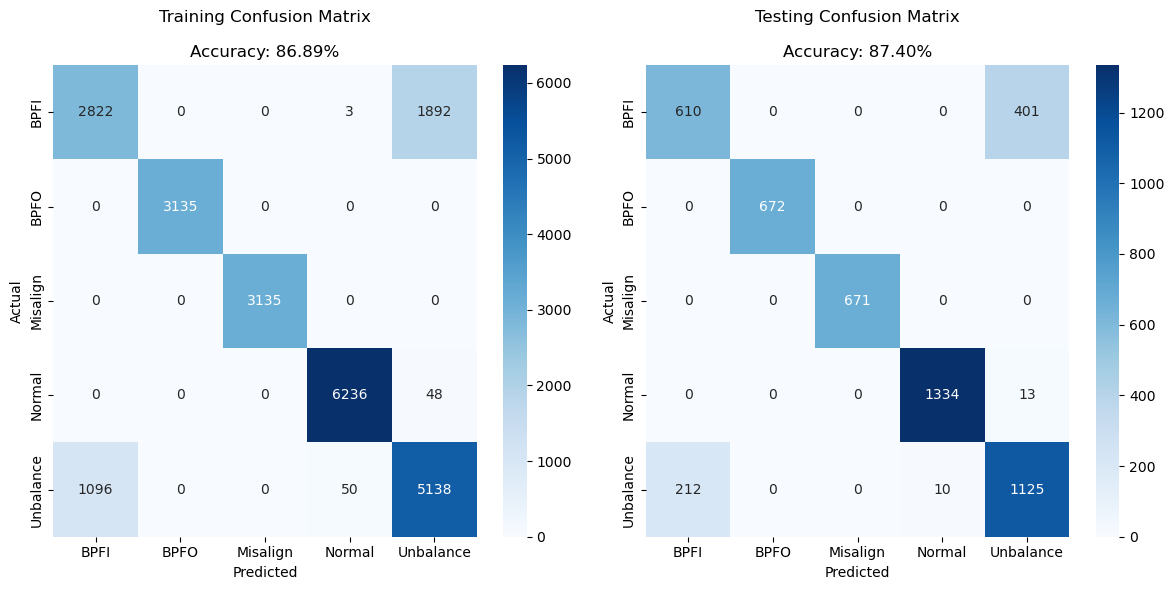

In [12]:
import seaborn as sns     
#Biểu đồ confusion matrix
plt.figure(figsize=(12, 6))# Kích thước biểu đồ
plt.subplot(1, 2, 1)# Vẽ biểu đồ đầu tiên trong 1 hàng 2 cột
sns.heatmap(train_cm, annot=True, fmt='d', cmap='Blues', 
xticklabels=Fault_types, yticklabels=Fault_types)# Vẽ heatmap với các nhãn trục x và y
plt.title(f'Training Confusion Matrix\n\nAccuracy: {train_accuracy*100:.2f}%' )# Tiêu đề biểu đồ
plt.xlabel('Predicted')# Nhãn trục x
plt.ylabel('Actual')# Nhãn trục y
plt.subplot(1, 2, 2)# Vẽ biểu đồ thứ hai trong 1 hàng 2 cột
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues',
xticklabels=Fault_types, yticklabels=Fault_types)# Vẽ heatmap với các nhãn trục x và y
plt.title(f'Testing Confusion Matrix\n\nAccuracy: {test_accuracy*100:.2f}%')# Tiêu đề biểu đồ
plt.xlabel('Predicted')# Nhãn trục x
plt.ylabel('Actual')# Nhãn trục y
plt.tight_layout()# Tự động điều chỉnh khoảng cách giữa các phần tử trong biểu đồ
plt.show()# Hiển thị biểu đồ


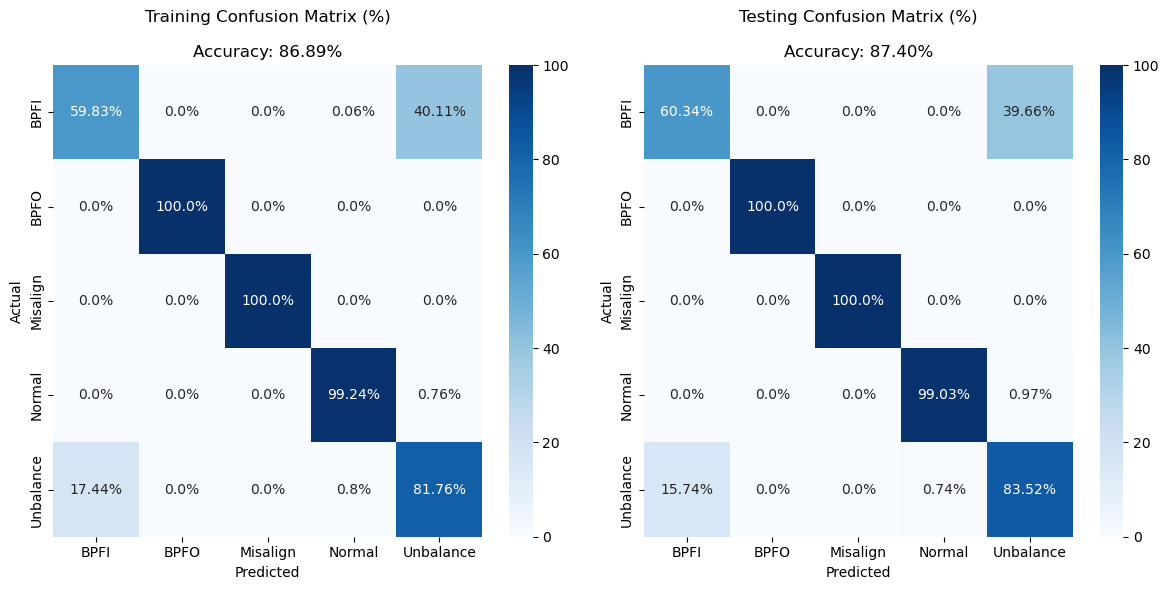

In [13]:
import numpy as np

# Chuẩn hóa theo hàng (Actual)
train_cm_percent = train_cm.astype('float') / train_cm.sum(axis=1, keepdims=True) * 100
test_cm_percent  = test_cm.astype('float') / test_cm.sum(axis=1, keepdims=True) * 100
import seaborn as sns
import matplotlib.pyplot as plt
annot_train = np.round(train_cm_percent, 2).astype(str) + '%'
annot_test  = np.round(test_cm_percent, 2).astype(str) + '%'

plt.figure(figsize=(12, 6))

# Training Confusion Matrix (%)
plt.subplot(1, 2, 1)
sns.heatmap(
    train_cm_percent,
    annot=annot_train,
    fmt='',
    cmap='Blues',
    xticklabels=Fault_types,
    yticklabels=Fault_types
)
plt.title(f'Training Confusion Matrix (%)\n\nAccuracy: {train_accuracy*100:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Testing Confusion Matrix (%)
plt.subplot(1, 2, 2)
sns.heatmap(
    test_cm_percent,
    annot=annot_test,
    fmt='',
    cmap='Blues',
    xticklabels=Fault_types,
    yticklabels=Fault_types
)
plt.title(f'Testing Confusion Matrix (%)\n\nAccuracy: {test_accuracy*100:.2f}%')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()
